# CV05 Segment Anything (SAM)

### Lab Description

This laboratory exercise introduces the **Segment Anything Model (SAM)**, a state-of-the-art foundation model for image segmentation developed by Meta AI. Unlike traditional segmentation models trained on a specific dataset, SAM can generalize to diverse images and tasks with minimal additional supervision. It can perform **automatic segmentation** as well as **prompt-based segmentation** using points, boxes, or masks.

In this hands-on lab, you will run inference with a pre-trained SAM checkpoint on your own images. You will measure inference efficiency, visualize segmentation results as overlays and colored segmentation maps, and analyze the trade-off between accuracy, mask count, and computational cost.

#### Recommended Hardware
AMD Ryzen™ AI Halo Processors (e.g., AI Max+ 395, AI Max 390)
#### Software Environment
OS: Ubuntu 24.04.3 LTS \
Install [AUP learning cloud](https://amdresearch.github.io/aup-learning-cloud/installation/quick-start.html?family=ryzen-ai&gpu=max-pro-395). After installing AUP Learning Cloud, you will have a ROCm and PyTorch environment that is compatible with this notebook.

## Goals

- Understand SAM's architecture (ViT backbone + mask decoder) as a foundation model
- Run SAM inference in automatic and prompt-based segmentation modes
- Measure per-image inference time and VRAM usage
- Visualize mask overlays and colored segmentation maps
- Analyze the trade-off between mask count, quality, and compute cost


In [1]:
import os
import sys

import torch
import torchvision

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA device:", torch.cuda.get_device_name(0))

Python: 3.12.3
PyTorch: 2.9.1+rocm7.13.0
Torchvision: 0.24.0+rocm7.13.0
CUDA available: True
CUDA device: Radeon 8060S Graphics


## 1. Dependencies (SAM)
The official Segment Anything package, OpenCV, and pycocotools are preinstalled in the CV course image.
> Note: **Model weights are not included**; the next steps download them.

## 2. Imports, Config, and Paths
- Define a simple config `CFG` for inference.
- Create **DATA_DIR** and **OUTPUT_DIR** using `os.path.expanduser("~/data")`.
- Inputs live under `~/data`:
  - the SAM checkpoint in `~/data/sam_checkpoints/` (e.g., `sam_vit_b.pth`)
  - test images in `~/data/sam_inputs/`

In [2]:
import glob
import time
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from segment_anything import SamAutomaticMaskGenerator, SamPredictor, sam_model_registry


@dataclass
class CFG:
    seed: int = 42
    # Choose one of: 'vit_h', 'vit_l', 'vit_b'
    sam_variant: str = "vit_b"
    # File name you upload under ~/data/sam_checkpoints/
    sam_ckpt_name: str = "sam_vit_b.pth"
    img_size_limit: int = 2048  # Max longer side before resizing for speed
    prompt_mode: str = "auto"  # 'auto' or 'points' (prompt-based)
    batch_size: int = 8  # Only for prompt batches when using 'points'
    device: str = "cuda" if torch.cuda.is_available() else "cpu"


cfg = CFG()

# Base paths (always under ~/data)
DATA_DIR = os.path.expanduser("~/data")
CKPT_DIR = os.path.join(DATA_DIR, "sam_checkpoints")
INPUT_DIR = os.path.join(DATA_DIR, "sam_inputs")
OUTPUT_DIR = os.path.join(DATA_DIR, "sam_outputs")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(INPUT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("DATA_DIR:", DATA_DIR)
print("CKPT_DIR:", CKPT_DIR)
print("INPUT_DIR:", INPUT_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)


def set_seed(seed=42):
    import random

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)
cfg

DATA_DIR: /home/jovyan/data
CKPT_DIR: /home/jovyan/data/sam_checkpoints
INPUT_DIR: /home/jovyan/data/sam_inputs
OUTPUT_DIR: /home/jovyan/data/sam_outputs


CFG(seed=42, sam_variant='vit_b', sam_ckpt_name='sam_vit_b.pth', img_size_limit=2048, prompt_mode='auto', batch_size=8, device='cuda')

## 3. Checkpoint & Images

1. If `~/data/sam_checkpoints/` has no checkpoint, the cell downloads the official **ViT-B** checkpoint (about 375 MB) from the [segment-anything repository](https://github.com/facebookresearch/segment-anything?tab=readme-ov-file) and saves it as `sam_vit_b.pth`.
2. If `~/data/sam_inputs/` is empty, it downloads three sample images (truck, dog, groceries) from the same repository.
3. To use your own images, upload JPG/PNG files to `~/data/sam_inputs/` before running the cell.

In [3]:
import urllib.request

SAM_CKPT_URLS = {
    "vit_b": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth",
    "vit_l": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_l_0b3195.pth",
    "vit_h": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth",
}
SAMPLE_IMAGE_URLS = [
    f"https://raw.githubusercontent.com/facebookresearch/segment-anything/main/notebooks/images/{name}"
    for name in ("truck.jpg", "dog.jpg", "groceries.jpg")
]

ckpt_path = os.path.join(CKPT_DIR, cfg.sam_ckpt_name)
if not os.path.exists(ckpt_path):
    print("Downloading checkpoint:", SAM_CKPT_URLS[cfg.sam_variant])
    urllib.request.urlretrieve(SAM_CKPT_URLS[cfg.sam_variant], ckpt_path)

input_images = sorted(glob.glob(os.path.join(INPUT_DIR, "*.*")))
if not input_images:
    print(f"No images in {INPUT_DIR}, downloading sample images")
    for url in SAMPLE_IMAGE_URLS:
        urllib.request.urlretrieve(url, os.path.join(INPUT_DIR, url.rsplit("/", 1)[-1]))
    input_images = sorted(glob.glob(os.path.join(INPUT_DIR, "*.*")))

print("Found checkpoint:", ckpt_path)
print("Found input images:", len(input_images))
print("Examples:", input_images[:5])

No images in /home/jovyan/data/sam_inputs, downloading sample images
Found checkpoint: /home/jovyan/data/sam_checkpoints/sam_vit_b.pth
Found input images: 3
Examples: ['/home/jovyan/data/sam_inputs/dog.jpg', '/home/jovyan/data/sam_inputs/groceries.jpg', '/home/jovyan/data/sam_inputs/truck.jpg']


## 4. Load SAM Model
We build a SAM model by variant and move it to the configured device.


In [4]:
sam = sam_model_registry[cfg.sam_variant](checkpoint=ckpt_path)
sam.to(device=cfg.device)
print(f"SAM ({cfg.sam_variant}) loaded on {cfg.device}")

SAM (vit_b) loaded on cuda


## 5. Utilities
- Resize images if longer side exceeds `img_size_limit` (to control latency/memory).  
- Track **peak VRAM**.  
- Helper to overlay masks on images and export both **overlay** and **binary mask PNGs**.


In [5]:
import cv2


def gpu_reset_peaks():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


def read_image_rgb(path):
    img = Image.open(path).convert("RGB")
    return np.array(img)


def maybe_resize(img: np.ndarray, limit: int) -> np.ndarray:
    h, w = img.shape[:2]
    if max(h, w) <= limit:
        return img
    if h >= w:
        new_h = limit
        new_w = int(w * (limit / h))
    else:
        new_w = limit
        new_h = int(h * (limit / w))
    return cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)


def draw_mask_overlay(image: np.ndarray, masks: list[dict]) -> np.ndarray:
    """Overlay semi-transparent masks on image."""
    out = image.copy()
    for m in masks:
        mask = m["segmentation"].astype(bool)
        # Random alpha; deterministic with seed
        color = np.random.default_rng(123).integers(0, 255, size=3, dtype=np.uint8)
        out[mask] = (0.6 * color + 0.4 * out[mask]).astype(np.uint8)
    return out


def save_masks(image_name: str, image: np.ndarray, masks: list[dict], out_dir: str):
    """Save overlay and per-mask PNGs."""
    base = os.path.splitext(os.path.basename(image_name))[0]
    overlay = draw_mask_overlay(image, masks)

    overlay_p = os.path.join(out_dir, f"{base}_overlay.png")
    Image.fromarray(overlay).save(overlay_p)

    # save raw mask stack as individual PNGs
    for i, m in enumerate(masks):
        mask = m["segmentation"].astype(np.uint8) * 255
        mask_p = os.path.join(out_dir, f"{base}_mask_{i:03d}.png")
        Image.fromarray(mask).save(mask_p)

    return overlay_p


def masks_to_colormap(image: np.ndarray, masks: list[dict]) -> np.ndarray:
    """
    Convert list of SAM masks into a single RGB segmentation map,
    where each mask region has a unique color.
    """
    h, w = image.shape[:2]
    seg_map = np.zeros((h, w, 3), dtype=np.uint8)

    rng = np.random.default_rng(42)  # fixed seed for reproducibility
    colors = rng.integers(0, 255, size=(len(masks), 3), dtype=np.uint8)

    for i, m in enumerate(masks):
        mask = m["segmentation"].astype(bool)
        seg_map[mask] = colors[i]

    return seg_map

## 6. Inference Modes
We provide two inference modes:

- **Auto mode**: `SamAutomaticMaskGenerator` produces a set of masks per image automatically.  
- **Points mode**: `SamPredictor` with a few pre-defined point prompts (demo).

> For this lab, default is `auto`. You can switch `cfg.prompt_mode` to `"points"` to test prompt-based inference.


In [6]:
def auto_masks_for_image(sam_model, image_rgb: np.ndarray) -> list[dict]:
    mask_generator = SamAutomaticMaskGenerator(
        model=sam_model,
        points_per_side=32,  # speed/quality trade-off (adjust for your GPU)
        pred_iou_thresh=0.86,
        stability_score_thresh=0.92,
        crop_n_layers=1,
        crop_n_points_downscale_factor=2,
        min_mask_region_area=100,  # remove small regions
    )
    return mask_generator.generate(image_rgb)


def point_prompt_masks(sam_model, image_rgb: np.ndarray) -> list[dict]:
    """
    Demo with two fixed prompts: a center-positive point and a corner-negative point.
    Students can modify points for exploration.
    """
    predictor = SamPredictor(sam_model)
    predictor.set_image(image_rgb)

    h, w = image_rgb.shape[:2]
    input_points = np.array(
        [
            [w // 2, h // 2],  # center positive
            [5, 5],  # top-left negative
        ]
    )
    input_labels = np.array([1, 0])  # 1 positive, 0 negative

    masks, scores, logits = predictor.predict(
        point_coords=input_points, point_labels=input_labels, multimask_output=True
    )

    # Convert to list[dict] to unify interface with auto mode
    out = []
    for i, m in enumerate(masks):
        out.append({"segmentation": m.astype(bool), "score": float(scores[i]), "logit_shape": logits[i].shape})
    return out

## 7. Run Inference
This will:
- Iterate over images in `INPUT_DIR`  
- Optionally resize to `cfg.img_size_limit`  
- Run SAM inference (auto or points mode)  
- Record **per-image time** and **peak VRAM** (global run)  
- Save **overlay & mask PNGs** to `OUTPUT_DIR`  
- Append to **log.txt** and create a **CSV** summary


In [7]:
epoch_times = []  # per-image timings
peak_vram_per_run = []  # peak VRAM (MB) recorded after each image
files_processed, masks_count = [], []

log_path = os.path.join(OUTPUT_DIR, "log.txt")
with open(log_path, "w") as f:
    f.write("image_name,batch_size,mode,infer_time_s,num_masks,peak_vram_MB\n")


def get_peak_vram_mb():
    return (torch.cuda.max_memory_allocated(cfg.device) / (1024**2)) if torch.cuda.is_available() else 0.0


gpu_reset_peaks()
for img_path in input_images:
    image = read_image_rgb(img_path)
    image = maybe_resize(image, cfg.img_size_limit)

    t0 = time.perf_counter()
    if cfg.prompt_mode == "auto":
        masks = auto_masks_for_image(sam, image)
        batch = 1
    else:
        masks = point_prompt_masks(sam, image)
        batch = cfg.batch_size  # conceptual batch for prompts
    t1 = time.perf_counter()

    # Save overlay + individual binary masks
    overlay_p = save_masks(os.path.basename(img_path), image, masks, OUTPUT_DIR)

    # NEW: save a colored segmentation map (each mask has a unique color)
    color_map = masks_to_colormap(image, masks)
    base = os.path.splitext(os.path.basename(img_path))[0]
    color_p = os.path.join(OUTPUT_DIR, f"{base}_colormap.png")
    Image.fromarray(color_map).save(color_p)

    # Stats
    infer_time = t1 - t0
    epoch_times.append(infer_time)
    files_processed.append(os.path.basename(img_path))
    masks_count.append(len(masks))

    peak = get_peak_vram_mb()
    peak_vram_per_run.append(peak)

    with open(log_path, "a") as f:
        f.write(f"{os.path.basename(img_path)},{batch},{cfg.prompt_mode},{infer_time:.3f},{len(masks)},{peak:.1f}\n")

print("Done. Log written to:", log_path)

# Build a CSV summary
df = pd.DataFrame(
    {
        "image_name": files_processed,
        "infer_time_s": epoch_times,
        "num_masks": masks_count,
        "peak_vram_MB": peak_vram_per_run,
    }
)
csv_path = os.path.join(OUTPUT_DIR, "sam_inference_report.csv")
df.to_csv(csv_path, index=False)
print("CSV report:", csv_path)
df.head()

MIOpen(HIP): Warning [ParseAndLoadDb] File is unreadable: "/usr/local/lib/python3.12/dist-packages/_rocm_sdk_libraries_gfx1151/share/miopen/db/gfx1151_20.HIP.fdb.txt"


Done. Log written to: /home/jovyan/data/sam_outputs/log.txt
CSV report: /home/jovyan/data/sam_outputs/sam_inference_report.csv


,image_name,infer_time_s,num_masks,peak_vram_MB
0,dog.jpg,27.556202,63,2869.781738
1,groceries.jpg,10.657214,137,2869.785645
2,truck.jpg,12.817213,83,4395.053223


## 8. Visualization
Display the **overlay** results and **colored segmentation maps** for a few processed images (already saved in `OUTPUT_DIR`).


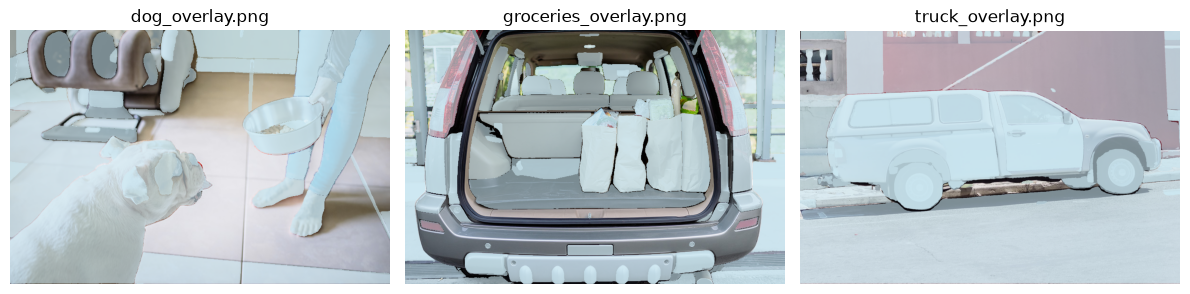

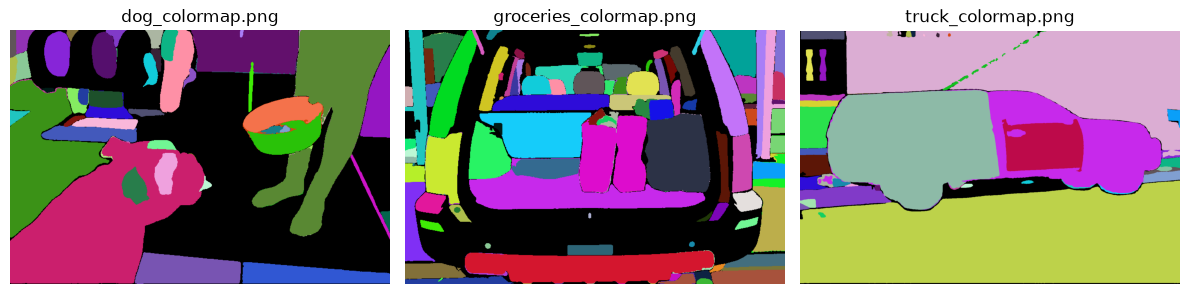

In [8]:
overlays = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*_overlay.png")))
n_show = min(6, len(overlays))
plt.figure(figsize=(12, 6))
for i in range(n_show):
    plt.subplot(2, 3, i + 1)
    im = Image.open(overlays[i]).convert("RGB")
    plt.imshow(im)
    plt.title(os.path.basename(overlays[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

# Look for all saved *_colormap.png files
colormaps = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*_colormap.png")))

n_show = min(6, len(colormaps))
plt.figure(figsize=(12, 6))
for i in range(n_show):
    plt.subplot(2, 3, i + 1)
    im = Image.open(colormaps[i]).convert("RGB")
    plt.imshow(im)
    plt.title(os.path.basename(colormaps[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Final Report
We print the configuration overview similar to previous labs (batch size, device, mode).


In [9]:
print("=== Inference Configuration ===")
print(f"SAM variant     : {cfg.sam_variant}")
print(f"Checkpoint file : {cfg.sam_ckpt_name}")
print(f"Prompt mode     : {cfg.prompt_mode}")
print(f"Batch size      : {cfg.batch_size}")
print(f"Image max side  : {cfg.img_size_limit}")
print(f"Device          : {cfg.device}")
print("\nArtifacts saved in:", OUTPUT_DIR)
print(" - log.txt")
print(" - sam_inference_report.csv")
print(" - *_overlay.png and *_mask_XXX.png files")

=== Inference Configuration ===
SAM variant     : vit_b
Checkpoint file : sam_vit_b.pth
Prompt mode     : auto
Batch size      : 8
Image max side  : 2048
Device          : cuda

Artifacts saved in: /home/jovyan/data/sam_outputs
 - log.txt
 - sam_inference_report.csv
 - *_overlay.png and *_mask_XXX.png files


## Conclusions

In this lab, you ran inference with the Segment Anything Model (SAM) on custom images. You explored both automatic and prompt-based segmentation modes, and analyzed the trade-off between segmentation quality, mask count, and computational cost.

---

Copyright (C) 2025 Advanced Micro Devices, Inc. All rights reserved. Portions of this file consist of AI-generated content.
SPDX-License-Identifier: MIT